# Hello Soft Clustering (GMM)

### T1. Using 3 mixtures, initialize your Gaussian with means (3,3), (2,2), and (-3,-3), and standard Covariance, I, the identity matrix. Use equal mix- ture weights as the initial weights. Repeat three iterations of EM. Write down $w_{n,j}$ , $m_j$ , $\vec{Î¼_j}$, $\Sigma_j$ for each EM iteration. (You may do the calculations by hand or write code to do so)



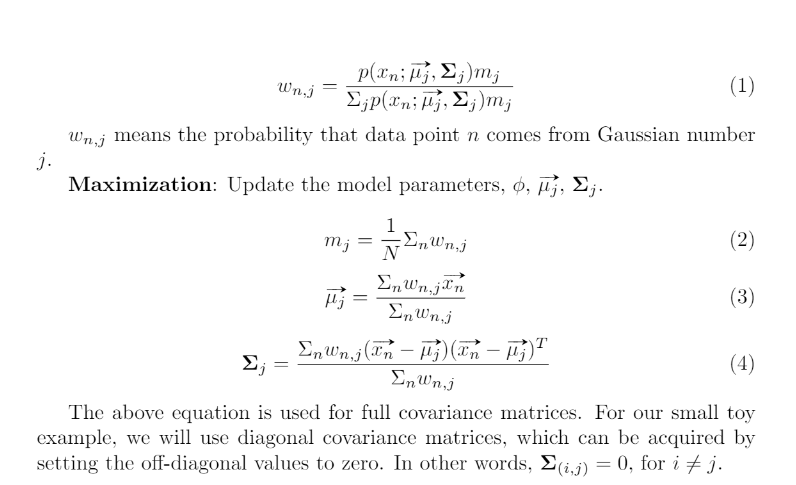

## TODO: Complete functions below including
- Fill relevant parameters in each function.
- Implement computation and return values.

These functions will be used in T1-4.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Hint: You can use this function to get gaussian distribution.
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.multivariate_normal.html
from scipy.stats import multivariate_normal

In [2]:
class GMM:
    def __init__(self, mixture_weight, mean_params, cov_params):
        """
        Initialize GMM.
        """
        # Copy construction values.
        self.mixture_weight = np.array(mixture_weight, dtype=float)
        self.mixture_weight = self.mixture_weight / self.mixture_weight.sum()

        self.mean_params = np.array(mean_params, dtype=float)
        self.cov_params = np.array(cov_params, dtype=float)

        # Initiailize iteration.
        self.n_iter = 0

    def _mv_gaussian_pdf(self, x, mu, Sigma):
        D = x.shape[0]
        eps = 1e-8

        # Stabilize Sigma to avoid singular matrix issues
        Sigma_stable = Sigma + eps * np.eye(D)

        det = np.linalg.det(Sigma_stable)
        inv = np.linalg.inv(Sigma_stable)

        diff = (x - mu).reshape(D, 1)
        exponent = -0.5 * (diff.T @ inv @ diff).item()

        norm_const = 1.0 / np.sqrt(((2 * np.pi) ** D) * det)
        return norm_const * np.exp(exponent)

    def estimation_step(self, data):
        """
        TODO: Perform estimation step. Then, return w_{n,j} in eq. 1)
        """
        # INSERT CODE HERE
        X = np.array(data, dtype=float)
        N, D = X.shape
        K = self.mixture_weight.shape[0]

        w = np.zeros((N, K), dtype=float)

        # compute numerator for each n,j
        for n in range(N):
            for j in range(K):
                p = self._mv_gaussian_pdf(X[n], self.mean_params[j], self.cov_params[j])
                w[n, j] = self.mixture_weight[j] * p

            # normalize so sum_j w[n,j] = 1
            denom = w[n].sum()
            if denom == 0:
                # if underflow happens, fallback to uniform
                w[n] = 1.0 / K
            else:
                w[n] /= denom

        return w


    def maximization_step(self, data, w):
        """
        TODO: Perform maximization step.
            (Update parameters in this GMM model.)
        """
        # INSERT CODE HERE
        X = np.array(data, dtype=float)
        N, D = X.shape
        K = w.shape[1]

        # effective number of points for each component
        Nk = w.sum(axis=0)  # shape (K,)

        # update mixture weights
        self.mixture_weight = Nk / N
        self.mixture_weight = self.mixture_weight / self.mixture_weight.sum()  # safety

        # update means
        new_means = np.zeros((K, D), dtype=float)
        for j in range(K):
            if Nk[j] == 0:
                new_means[j] = self.mean_params[j]  # keep old if dead component
            else:
                new_means[j] = (w[:, j].reshape(N, 1) * X).sum(axis=0) / Nk[j]
        self.mean_params = new_means

        # update covariances
        new_covs = np.zeros((K, D, D), dtype=float)
        for j in range(K):
            if Nk[j] == 0:
                new_covs[j] = self.cov_params[j]
                continue

            cov = np.zeros((D, D), dtype=float)
            for n in range(N):
                diff = (X[n] - self.mean_params[j]).reshape(D, 1)
                cov += w[n, j] * (diff @ diff.T)

            cov /= Nk[j]

            # enforce DIAGONAL covariance (HW3 requirement)
            cov = np.diag(np.diag(cov))

            # numerical stability
            cov += 1e-8 * np.eye(D)

            new_covs[j] = cov

        self.cov_params = new_covs


    def get_log_likelihood(self, data):
        """
        TODO: Compute log likelihood.
        """
        # INSERT CODE HERE
        X = np.array(data, dtype=float)
        N, D = X.shape
        K = self.mixture_weight.shape[0]

        ll = 0.0
        eps = 1e-300  # prevent log(0)

        for n in range(N):
            s = 0.0
            for j in range(K):
                p = self._mv_gaussian_pdf(X[n], self.mean_params[j], self.cov_params[j])
                s += self.mixture_weight[j] * p
            ll += np.log(s + eps)

        return ll

    def print_iteration(self):
        print("m :\n", self.mixture_weight)
        print("mu :\n", self.mean_params)
        print("covariance matrix :\n", self.cov_params)
        print("-------------------------------------------------------------")

    def perform_em_iterations(self, data, num_iterations, display=True):
        """
        Perform estimation & maximization steps with num_iterations.
        Then, return list of log_likelihood from those iterations.
        """
        log_prob_list = []

        # Display initialization.
        if display:
            print("Initialization")
            self.print_iteration()

        for n_iter in range(num_iterations):

            # TODO: Perform EM step.
            # INSERT CODE HERE
            # E-step
            w = self.estimation_step(data)

            # M-step
            self.maximization_step(data, w)

            # Calculate log prob
            log_prob = self.get_log_likelihood(data)
            log_prob_list.append(log_prob)

            self.n_iter += 1

            # Display each iteration.
            if display:
                print(f"Iteration: {n_iter}")
                print("w :\n", w)
                self.print_iteration()

        return log_prob_list

In [3]:
num_iterations = 3
num_mixture = 3
mixture_weight = [1] * num_mixture # m
mean_params = np.array([[3,3], [2,2], [-3,-3]], dtype = float)
cov_params = np.array([np.eye(2)] * num_mixture)

X, Y = np.array([1, 3, 2, 8, 6, 7, -3, -2, -7]), np.array([2, 3, 2, 8, 6, 7, -3, -4, -7])
data = np.vstack([X,Y]).T

gmm = GMM(mixture_weight, mean_params, cov_params)
log_prob_list = gmm.perform_em_iterations(data, num_iterations)

Initialization
m :
 [0.33333333 0.33333333 0.33333333]
mu :
 [[ 3.  3.]
 [ 2.  2.]
 [-3. -3.]]
covariance matrix :
 [[[1. 0.]
  [0. 1.]]

 [[1. 0.]
  [0. 1.]]

 [[1. 0.]
  [0. 1.]]]
-------------------------------------------------------------
Iteration: 0
w :
 [[1.19202924e-01 8.80797074e-01 1.81545844e-09]
 [7.31058577e-01 2.68941423e-01 1.69570767e-16]
 [2.68941423e-01 7.31058577e-01 1.01529030e-11]
 [9.99983299e-01 1.67014237e-05 2.03106069e-42]
 [9.99088949e-01 9.11051258e-04 5.37528840e-32]
 [9.99876605e-01 1.23394587e-04 3.30529550e-37]
 [2.31952367e-16 1.38879473e-11 1.00000000e+00]
 [2.31952367e-16 1.38879473e-11 1.00000000e+00]
 [3.30570340e-37 5.90009438e-29 1.00000000e+00]]
m :
 [0.45757242 0.20909425 0.33333333]
mu :
 [[ 5.78992692  5.81887265]
 [ 1.67718211  2.14523106]
 [-4.         -4.66666666]]
covariance matrix :
 [[[4.53619415 0.        ]
  [0.         4.28700613]]

 [[0.51645581 0.        ]
  [0.         0.13152619]]

 [[4.66666669 0.        ]
  [0.         2.888888

### T2. Plot the log likelihood of the model given the data after each EM step. In other words, plot $\log \prod_n p( \vec{x_n} |Ï†, \vec{Î¼} , Î£)$. Does it goes up every iteration just as we learned in class?



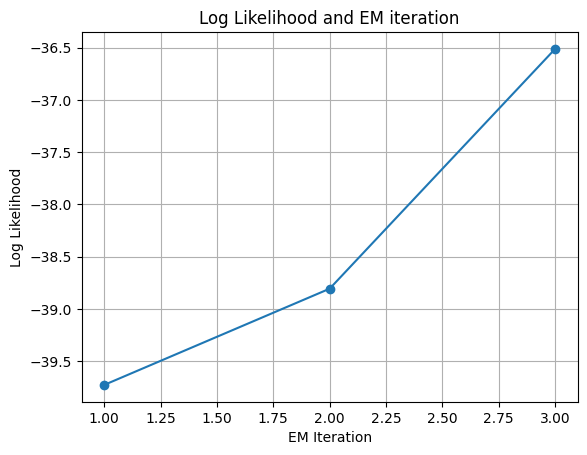

In [4]:
plt.figure()
plt.plot(np.arange(1, len(log_prob_list) + 1), log_prob_list, marker="o")
plt.xlabel("EM Iteration")
plt.ylabel("Log Likelihood")
plt.title("Log Likelihood and EM iteration")
plt.grid(True)
plt.show()

**ANS:**  The log-likelihood goes up (becomes less negative) in each step. This means the log-likelihood is improving, which matches what we learned in class.

### T3. Using 2 mixtures, initialize your Gaussian with means (3,3) and (-3,-3), and standard Covariance, I, the identity matrix. Use equal mixture weights as the initial weights. Repeat three iterations of EM. Write down $w_{n,j}$ , $m_j$ , $\vec{Î¼_j}$, $\Sigma_j$ for each EM iteration.



In [5]:
num_mixture = 2
mixture_weight = [1] * num_mixture

mean_params = np.array([[3,3], [-3,-3]], dtype = float)
cov_params = np.array([np.eye(2)] * num_mixture)

# INSERT CODE HERE
gmm2 = GMM(mixture_weight, mean_params, cov_params)
log_prob_list2 = gmm2.perform_em_iterations(data, num_iterations=num_iterations, display=True)

Initialization
m :
 [0.5 0.5]
mu :
 [[ 3.  3.]
 [-3. -3.]]
covariance matrix :
 [[[1. 0.]
  [0. 1.]]

 [[1. 0.]
  [0. 1.]]]
-------------------------------------------------------------
Iteration: 0
w :
 [[9.99999985e-01 1.52299823e-08]
 [1.00000000e+00 2.31952367e-16]
 [1.00000000e+00 3.77513545e-11]
 [1.00000000e+00 2.03109461e-42]
 [1.00000000e+00 5.38019003e-32]
 [1.00000000e+00 3.30570340e-37]
 [2.31952367e-16 1.00000000e+00]
 [2.31952367e-16 1.00000000e+00]
 [3.30570340e-37 1.00000000e+00]]
m :
 [0.66666666 0.33333334]
mu :
 [[ 4.50000001  4.66666667]
 [-3.99999997 -4.66666663]]
covariance matrix :
 [[[6.91666666 0.        ]
  [0.         5.8888889 ]]

 [[4.66666678 0.        ]
  [0.         2.88888911]]]
-------------------------------------------------------------
Iteration: 1
w :
 [[9.99879274e-01 1.20725839e-04]
 [9.99999741e-01 2.59403385e-07]
 [9.99975922e-01 2.40783356e-05]
 [1.00000000e+00 9.39286842e-19]
 [1.00000000e+00 7.41043286e-14]
 [1.00000000e+00 2.98366434e-16]
 

### T4. Plot the log likelihood of the model given the data after each EM step. Compare the log likelihood between using two mixtures and three mixtures. Which one has the better likelihood?

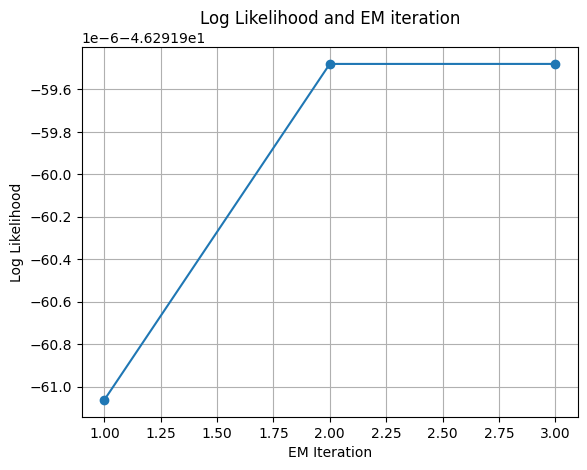

In [6]:
# TODO: Plot log_likelihood from T3
plt.figure()
plt.plot(np.arange(1, len(log_prob_list2) + 1), log_prob_list2, marker="o")
plt.xlabel("EM Iteration")
plt.ylabel("Log Likelihood")
plt.title("Log Likelihood and EM iteration")
plt.grid(True)
plt.show()

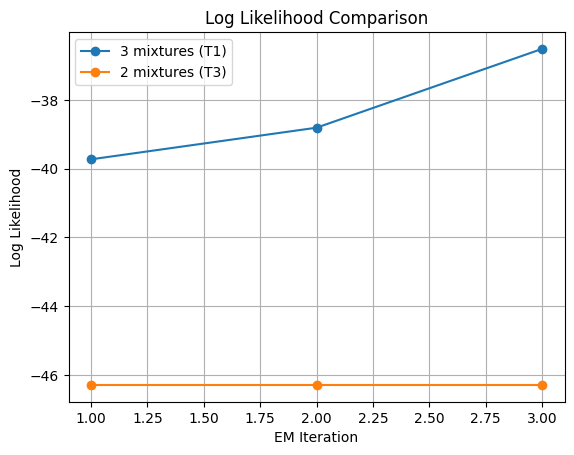

In [7]:
# TODO: Plot Comparision of log_likelihood from T1 and T3
plt.figure()
plt.plot(np.arange(1, len(log_prob_list) + 1), log_prob_list, marker="o", label="3 mixtures (T1)")
plt.plot(np.arange(1, len(log_prob_list2) + 1), log_prob_list2, marker="o", label="2 mixtures (T3)")
plt.xlabel("EM Iteration")
plt.ylabel("Log Likelihood")
plt.title("Log Likelihood Comparison")
plt.legend()
plt.grid(True)
plt.show()

**ANS:** The 3-mixture model has the better likelihood because its has higher log-likelihood than 2-mixture model.

# The face database

In [8]:
# Download facedata for google colab
!wget -nc https://github.com/ekapolc/Pattern_2024/raw/main/HW/HW03/facedata_mat.zip
!unzip facedata_mat.zip

--2026-02-11 16:30:02--  https://github.com/ekapolc/Pattern_2024/raw/main/HW/HW03/facedata_mat.zip
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/ekapolc/Pattern_2024/main/HW/HW03/facedata_mat.zip [following]
--2026-02-11 16:30:03--  https://raw.githubusercontent.com/ekapolc/Pattern_2024/main/HW/HW03/facedata_mat.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 953320 (931K) [application/zip]
Saving to: â€˜facedata_mat.zipâ€™

facedata_mat.zip    100%[===================>] 930.98K  --.-KB/s    in 0.007s  

2026-02-11 16:30:03 (127 MB/s) - â€˜facedata_mat.zipâ€™ saved [953320/953320]

Archive

In [9]:
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from skimage import img_as_float

# Change path to your facedata.mat file.
facedata_path = 'facedata.mat'

data = scipy.io.loadmat(facedata_path)
data_size = data['facedata'].shape

%matplotlib inline
data_size

(40, 10)

### Preprocess xf

In [10]:
xf = np.zeros((data_size[0], data_size[1], data['facedata'][0,0].shape[0], data['facedata'][0,0].shape[1]))
for i in range(data['facedata'].shape[0]):
    for j in range(data['facedata'].shape[1]):
        xf[i,j] = img_as_float(data['facedata'][i,j])

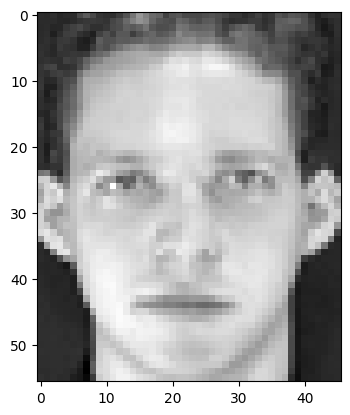

In [11]:
# Example: Ploting face image.
plt.imshow(xf[0,0], cmap = 'gray')
plt.show()

### T5. What is the Euclidean distance between xf[0,0] and xf[0,1]? What is the Euclidean distance between xf[0,0] and xf[1,0]? Does the numbers make sense? Do you think these numbers will be useful for face verification?

In [12]:
def L2_dist(x1, x2):
    """
    TODO: Calculate L2 distance.
    """
    dist = np.linalg.norm(x1 - x2)
    return dist

# Test L2_dist
def test_L2_dist():
    assert L2_dist(np.array([1, 2, 3]), np.array([1, 2, 3])) == 0.0
    assert  L2_dist(np.array([0, 0, 0]), np.array([1, 2, 3])) == np.sqrt(14)

test_L2_dist()

print('Euclidean distance between xf[0,0] and xf[0,1] is', L2_dist(xf[0,0], xf[0,1]))
print('Euclidean distance between xf[0,0] and xf[1,0] is', L2_dist(xf[0,0], xf[1,0]))

Euclidean distance between xf[0,0] and xf[0,1] is 10.037616294165492
Euclidean distance between xf[0,0] and xf[1,0] is 8.173295099737281


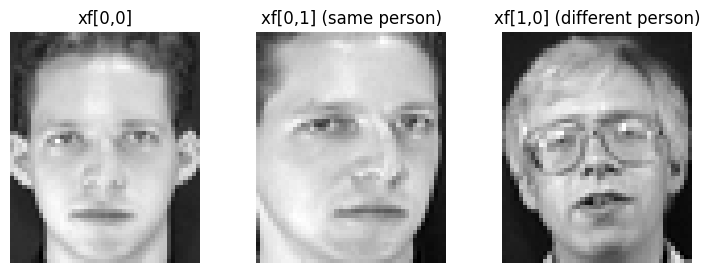

In [13]:
# TODO: Show why does the numbers make sense
plt.figure(figsize=(9,3))

plt.subplot(1,3,1)
plt.imshow(xf[0,0], cmap='gray')
plt.title("xf[0,0]")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(xf[0,1], cmap='gray')
plt.title("xf[0,1] (same person)")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(xf[1,0], cmap='gray')
plt.title("xf[1,0] (different person)")
plt.axis("off")

plt.show()

  ANS : The numbers make sense because pixel values are very sensitive to lighting and small variations. Even images of the same person (xf[0,0] and xf[0,1]) can have large differences due to lighting or expression changes, while images of different people may sometimes look numerically closer in pixel space. Therefore, raw pixel Euclidean distance is not reliable for face verification.

### T6. Write a function that takes in a set of feature vectors T and a set of feature vectors D, and then output the similarity matrix A. Show the matrix as an image. Use the feature vectors from the first 3 images from all 40 people for list T (in order x[0, 0], x[0, 1], x[0, 2], x[1, 0], x[1, 1], ...x[39, 2]). Use the feature vectors from the remaining 7 images from all 40 people for list D (in order x[0, 3], x[0, 4], x[0, 5], x[1, 6], x[0, 7], x[0, 8], x[0, 9], x[1, 3], x[1, 4]...x[39, 9]). We will treat T as our training images and D as our testing images

In [14]:
def organize_shape(matrix):
    """
    TODO (Optional): Reduce matrix dimension of 2D image to 1D and merge people and image dimension.
    This function can be useful at organizing matrix shapes.

    Example:
        Input shape: (people_index, image_index, image_shape[0], image_shape[1])
        Output shape: (people_index*image_index, image_shape[0]*image_shape[1])
    """
    P, I, H, W = matrix.shape
    return matrix.reshape(P * I, H * W)


def generate_similarity_matrix(A, B):
    """
    TODO: Calculate similarity matrix M,
    which M[i, j] is a distance between A[i] and B[j].
    """
    # INSERT CODE HERE
    A = np.array(A, dtype=float)
    B = np.array(B, dtype=float)

    # broadcasting: (nA,1,d) - (1,nB,d) -> (nA,nB,d)
    diff = A[:, None, :] - B[None, :, :]
    similarity_matrix = np.linalg.norm(diff, axis=2)
    return similarity_matrix

def test_generate_similarity_matrix():
    test_A = np.array([[1, 2],[3,4]])
    test_B = np.array([[1, 2], [5, 6], [7, 8]])
    expected_matrix = np.sqrt(np.array([[0, 32, 72], [8, 8, 32]]))
    assert (generate_similarity_matrix(test_A, test_B) == expected_matrix).all()

test_generate_similarity_matrix()

In [15]:
#TODO: Show similariry matrix between T and D.
T_imgs = xf[:, :3, :, :]
D_imgs = xf[:, 3:, :, :]
T = organize_shape(T_imgs)
D = organize_shape(D_imgs)
similarity_matrix = generate_similarity_matrix(T, D)

In [16]:
print("T shape:", T.shape)
print("D shape:", D.shape)
print("similarity_matrix shape:", similarity_matrix.shape)

T shape: (120, 2576)
D shape: (280, 2576)
similarity_matrix shape: (120, 280)


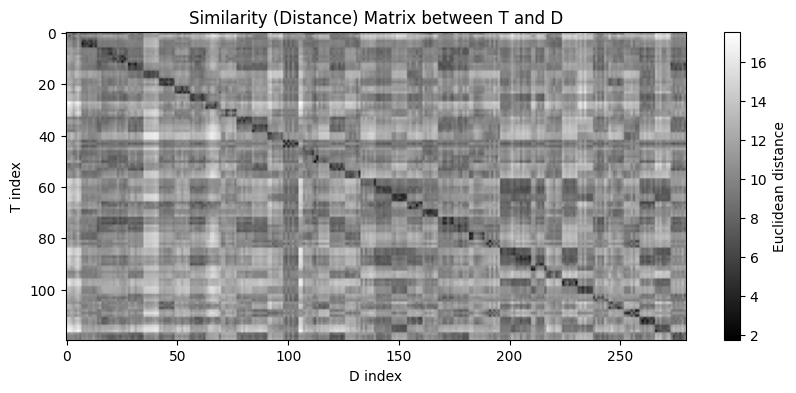

In [17]:
plt.figure(figsize=(10,4))
plt.imshow(similarity_matrix, aspect="auto", cmap="gray")
plt.colorbar(label="Euclidean distance")
plt.title("Similarity (Distance) Matrix between T and D")
plt.xlabel("D index")
plt.ylabel("T index")
plt.show()

### T7. From the example similarity matrix above, what does the black square between [5:10,5:10] suggest about the pictures from person number 2? What do the patterns from person number 1 say about the images from person 1?


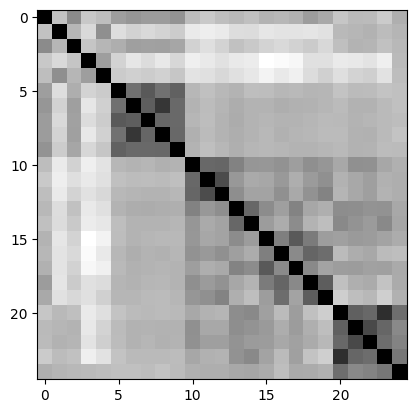

In [18]:
# INSERT CODE HERE
new_T = organize_shape(xf[:5, :5])
plt.imshow(generate_similarity_matrix(new_T, new_T), cmap="gray")

**ANS :** It shows very small distances meaning person 2â€™s images are very similar to each other.

The block pattern for person 1 also shows low distances within their images, indicating that images of the same person cluster together.

This means both images are same person.

 picture are sa### T8. Write a function that takes in the similarity matrix created from the previous part, and a threshold t as inputs. The outputs of the function are the true positive rate and the false alarm rate of the face verification task (280 Test images, tested on 40 people, a total of 11200 testing per threshold). What is the true positive rate and the false alarm rate for t = 10?

In [19]:
def evaluate_performance(similarity_matrix, threshold):
    """
    TODO: Calculate true positive rate and false alarm rate from given similarity_matrix and threshold.
    """
    # INSERT CODE HERE
    num_people = 40
    train_per_person = 3
    test_per_person = 7

    TP = 0
    FP = 0

    total_pos = num_people * test_per_person
    total_neg = total_pos * (num_people - 1)

    for test_person in range(num_people):
        col_start = test_person * test_per_person
        col_end   = col_start + test_per_person

        for j in range(col_start, col_end):
            for claim_person in range(num_people):

                row_start = claim_person * train_per_person
                row_end   = row_start + train_per_person

                dmin = similarity_matrix[row_start:row_end, j].min()

                if dmin <= threshold:
                    if claim_person == test_person:
                        TP += 1
                    else:
                        FP += 1

    true_pos_rate = TP / total_pos
    false_pos_rate = FP / total_neg
    return true_pos_rate, false_pos_rate

# Quick check
# (true_pos_rate, false_pos_rate) should be (0.9928571428571429, 0.33507326007326005)
evaluate_performance(similarity_matrix, 9.5)

(0.9928571428571429, 0.33507326007326005)

In [20]:
# INSERT CODE HERE
tpr, far = evaluate_performance(similarity_matrix, 10)
print("true_pos_rate =", tpr)
print("false_pos_rate =", far)

true_pos_rate = 0.9964285714285714
false_pos_rate = 0.4564102564102564


**ANS:** threshold=10, the true_pos_rate are 0.9964285714285714 and the false_pos_rate0.4564102564102564.

### T9. Plot the RoC curve for this simple verification system. What should be the minimum threshold to generate the RoC curve? What should be the maximum threshold? Your RoC should be generated from at least 1000 threshold levels equally spaced between the minimum and the maximum. (You should write a function for this).

In [21]:
def calculate_roc(input_mat):
    """
    TODO: Calculate a list of true_pos_rate and a list of false_pos_rate from the given matrix.
    """
    # INSERT CODE HERE
    t_min = np.min(input_mat)
    t_max = np.max(input_mat)

    thresholds = np.linspace(t_min, t_max, 1000)

    tpr_list = []
    far_list = []

    for t in thresholds:
        tpr, far = evaluate_performance(input_mat, t)
        tpr_list.append(tpr)
        far_list.append(far)

    return tpr_list, far_list

def plot_roc(input_mat):
    """
    TODO: Plot RoC Curve from a given matrix.
    """
    # INSERT CODE HERE
    tpr_list, far_list = calculate_roc(input_mat)

    plt.figure(figsize=(6,6))
    plt.plot(far_list, tpr_list)
    plt.xlabel("False Alarm Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.grid(True)
    plt.show()

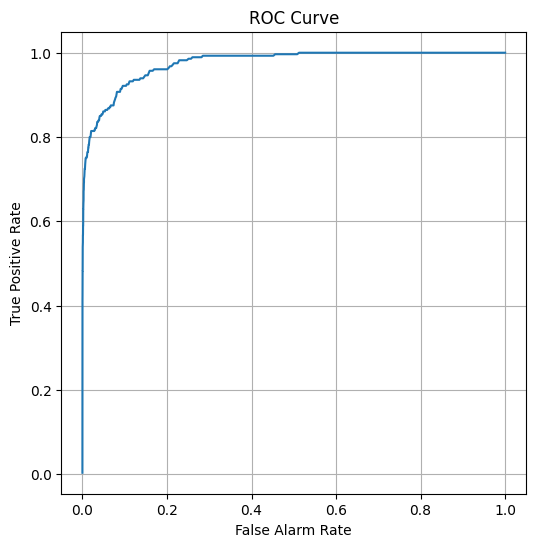

In [22]:
# INSERT CODE HERE
plot_roc(similarity_matrix)

In [23]:
t_min = np.min(similarity_matrix)
t_max = np.max(similarity_matrix)

print("Minimum threshold =", t_min)
print("Maximum threshold =", t_max)

Minimum threshold = 1.7420153428787784
Maximum threshold = 17.541726165424688


**ANS:**   Minimum and maximum value in the similiarity matrix are 1.7420153428787784 and 17.541726165424688 consecutivly.

### T10. What is the EER (Equal Error Rate)? What is the recall rate at 0.1% false alarm rate? (Write this in the same function as the previous question)



In [24]:
# You can add more parameter(s) to the function in the previous question.

# EER should be either 0.9071428571428571 or 0.9103759398496248 depending on method.
# Recall rate at 0.1% false alarm rate should be 0.5428571428571428.
tpr_list, fpr_list = calculate_roc(similarity_matrix)

tpr_list = np.array(tpr_list)
fpr_list = np.array(fpr_list)

In [25]:
fnr_list = 1 - tpr_list

print("EER :",tpr_list[np.argmin(np.abs(fpr_list - fnr_list))])
print("Recall at 0.001 false alarm rate :",tpr_list[np.argmin(np.abs(fpr_list - 0.001))])

EER : 0.9071428571428571
Recall at 0.001 false alarm rate : 0.5428571428571428


    ANS:

### T11. Compute the mean vector from the training images. Show the vector as an image (use numpy.reshape()). This is typically called the meanface (or meanvoice for speech signals). You answer should look exactly like the image shown below.

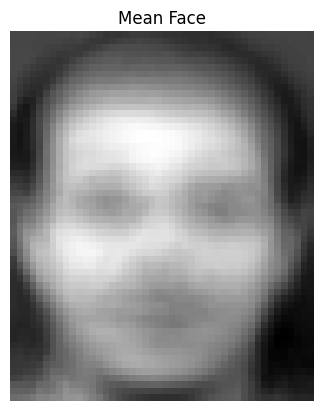

In [26]:
# INSERT CODE HERE
T = xf[:, :3]
T_flat = T.reshape(-1, T.shape[2] * T.shape[3])
mean_vector = np.mean(T_flat, axis=0)

meanface = mean_vector.reshape(T.shape[2], T.shape[3])

plt.imshow(meanface, cmap='gray')
plt.title("Mean Face")
plt.axis("off")
plt.show()

### T12. What is the size of the covariance matrix? What is the rank of the covariance matrix?


In [27]:
# TODO: Find the size and the rank of the covariance matrix.
num_samples = T_flat.shape[0]
num_pixels  = T_flat.shape[1]

print("Size of covariance matrix:", num_pixels, "x", num_pixels)
print("Rank of covariance matrix:", min(num_samples - 1, num_pixels))

Size of covariance matrix: 2576 x 2576
Rank of covariance matrix: 119


ANS:


### T13. What is the size of the Gram matrix? What is the rank of Gram matrix? If we compute the eigenvalues from the Gram matrix, how many non- zero eigenvalues do we expect to get?

In [28]:
# TODO: Compute gram matrix.
X = T_flat - mean_vector
gram_matrix = X @ X.T

In [29]:
# TODO: Show size and rank of Gram matrix.
print("Size of Gram matrix:", gram_matrix.shape)
print("Rank of Gram matrix:", np.linalg.matrix_rank(gram_matrix))

Size of Gram matrix: (120, 120)
Rank of Gram matrix: 119


ANS: non-zero eigenvalues = rank = 119


## T14. Is the Gram matrix also symmetric? Why?


**ANS:** Yes because it is X multiply transpose of X

### T15. Compute the eigenvectors and eigenvalues of the Gram matrix, v 0 and Î». Sort the eigenvalues and eigenvectors in descending order so that the first eigenvalue is the highest, and the first eigenvector corresponds to the best direction. How many non-zero eigenvalues are there? If you see a very small value, it is just numerical error and should be treated as zero.




In [30]:
# Hint: https://numpy.org/doc/stable/reference/generated/numpy.linalg.eigh.html

def calculate_eigenvectors_and_eigenvalues(matrix):
    """
    TODO: Calculate eigenvectors and eigenvalues,
    then sort the eigenvalues and eigenvectors in descending order.

    Hint: https://numpy.org/doc/stable/reference/generated/numpy.linalg.eigh.html
    """

    # INSERT CODE HERE
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    eigenvalues = eigenvalues[::-1]
    eigenvectors = eigenvectors[:, ::-1]

    return eigenvalues, eigenvectors

eigenvalues, eigenvectors = calculate_eigenvectors_and_eigenvalues(gram_matrix)

def test_eigenvalues_eigenvectors():
    # Dot product of an eigenvector pair should equal to zero.
    assert np.round(eigenvectors[10].dot(eigenvectors[20]), 10) == 0.0

    # Check if eigenvalues are sorted.
    assert list(eigenvalues) == sorted(eigenvalues, reverse = True)

test_eigenvalues_eigenvectors()

In [31]:
gram_eigenvalues, gram_eigenvectors = calculate_eigenvectors_and_eigenvalues(gram_matrix)

In [32]:
print("non-zero eigenvalues of gram matrix", np.sum(gram_eigenvalues>1e-2))
print("shape of gram_eigenvalues", gram_eigenvalues.shape)
print("shape of gram_eigenvectors", gram_eigenvectors.shape)

non-zero eigenvalues of gram matrix 119
shape of gram_eigenvalues (120,)
shape of gram_eigenvectors (120, 120)


ANS:
* non-zero eigenvalues of gram matrix 119
* Shape of gram_eigenvalues (120)
* Shape of gram_eigenvectors (120, 120)

### T16. Plot the eigenvalues. Observe how fast the eigenvalues decrease. In class, we learned that the eigenvalues is the size of the variance for each eigenvector direction. If I want to keep 95% of the variance in the data, how many eigenvectors should I use?

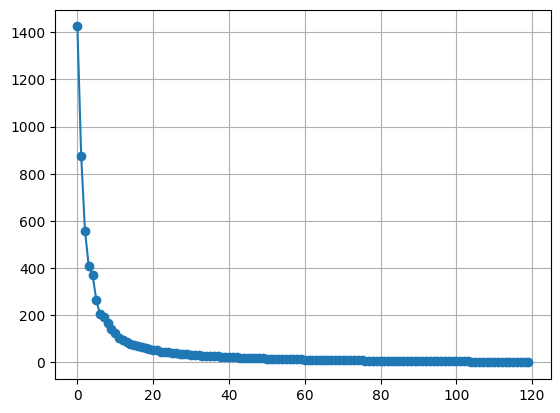

64


In [33]:
# INSERT CODE HERE
plt.plot(np.arange(len(eigenvalues)),eigenvalues,"-",marker="o")
plt.grid(True)
plt.show()

total_variance = gram_eigenvalues.sum()

idx = 0
curr_var = 0
while curr_var < total_variance*0.95 or idx >= len(gram_eigenvalues):
    curr_var += gram_eigenvalues[idx]
    idx += 1
print(idx)

ANS: 64 eigenvectors

### T17. Compute $\vec{v}$ . Donâ€™t forget to renormalize so that the norm of each vector is 1 (you can use numpy.linalg.norm). Show the first 10 eigenvectors as images. Two example eigenvectors are shown below. We call these images eigenfaces (or eigenvoice for speech signals).

In [34]:
# TODO: Compute v, then renormalize it.
X_train = T.reshape(120,-1).T
X_hat = X_train - meanface.reshape(-1,1)

# INSERT CODE HERE
v = X_hat @ eigenvectors
v /= np.linalg.norm(v, axis=0)

In [35]:
def test_eignevector_cov_norm(v):
    assert (np.round(np.linalg.norm(v, axis=0), 1) == 1.0).all()

test_eignevector_cov_norm(v)

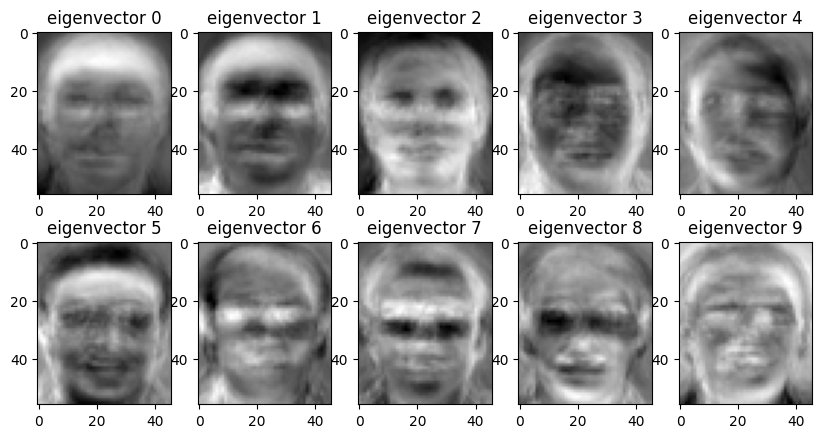

In [36]:
# TODO: Show the first 10 eigenvectors as images.
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.title("eigenvector "+str(i))
    plt.imshow(v[:, i].reshape(56,46), cmap='gray')

### T18. From the image, what do you think the first eigenvector captures? What about the second eigenvector? Look at the original images, do you think biggest variance are capture in these two eigenvectors?

**ANS:** The first eigenvector mainly captures overall lighting and strong variation around the hair area. The second captures facial structure differences like hair, eyes, and mouth. Yes, they represent the largest variance in the data, but they donâ€™t capture all facial details.

### T19. Find the projection values of all images. Keep the first k = 10 projection values. Repeat the simple face verification system we did earlier using these projected values. What is the EER and the recall rate at 0.1% FAR?

In [40]:
print("T shape:", T.shape)
print("v shape:", v.shape)

T shape: (40, 3, 56, 46)
v shape: (2576, 120)


In [43]:
T = xf[:, :3].reshape(-1, 56*46)   # (120, 2576)
D = xf[:, 3:].reshape(-1, 56*46)   # (280, 2576)

In [44]:
def calculate_projection_vectors(matrix, meanface, v, k=None):
    """
    TODO: Find the projection vectors on v from given matrix and meanface.
    """

    # INSERT CODE HERE
    Xc = matrix-meanface
    if k==None:
        projection_vectors = np.matmul(Xc, v[:, :])
    else:
        projection_vectors = np.matmul(Xc, v[:, :k])

    return projection_vectors

In [45]:
# TODO: Get projection vectors of T and D, then Keep first k projection values.
k = 10
T_reduced = calculate_projection_vectors(T, mean_vector, v, k=k)
D_reduced = calculate_projection_vectors(D, mean_vector, v, k=k)


def test_reduce_dimension():
    assert T_reduced.shape[-1] == k
    assert D_reduced.shape[-1] == k

test_reduce_dimension()

In [46]:
# TODO: Find EER and the recall rate at 0.1% FAR.
reduced_similarity_matrix = generate_similarity_matrix(T_reduced, D_reduced)

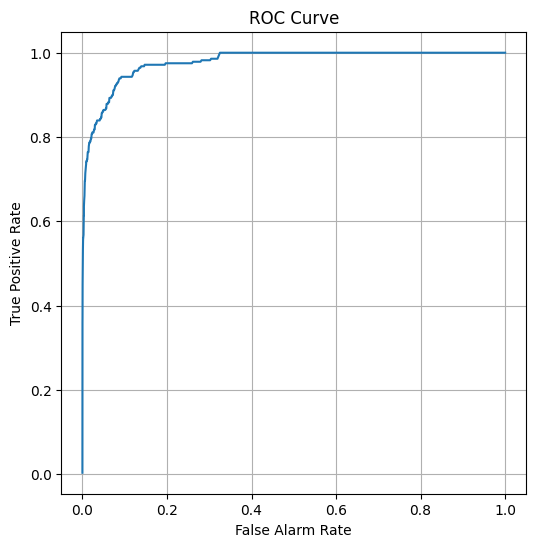

EER 0.9071428571428571
Recall 0.5428571428571428


In [48]:
plot_roc(reduced_similarity_matrix)
print("EER",tpr_list[np.argmin(np.abs(fpr_list - fnr_list))])
print("Recall",tpr_list[np.argmin(np.abs(fpr_list - 0.001))])

ANS:
* EER = 0.9071428571428571
* Recall = 0.5464285714285714

### T20. What is the k that gives the best EER? Try k = 5, 6, 7, 8, 9, 10, 11, 12, 13, 14.


k=5 | EER=0.1071 | Recall@0.1%FAR=0.2536
k=6 | EER=0.0941 | Recall@0.1%FAR=0.3500
k=7 | EER=0.0928 | Recall@0.1%FAR=0.4107
k=8 | EER=0.0858 | Recall@0.1%FAR=0.4071
k=9 | EER=0.0802 | Recall@0.1%FAR=0.4500
k=10 | EER=0.0788 | Recall@0.1%FAR=0.5179
k=11 | EER=0.0783 | Recall@0.1%FAR=0.5036
k=12 | EER=0.0849 | Recall@0.1%FAR=0.5107
k=13 | EER=0.0816 | Recall@0.1%FAR=0.5143
k=14 | EER=0.0826 | Recall@0.1%FAR=0.5036


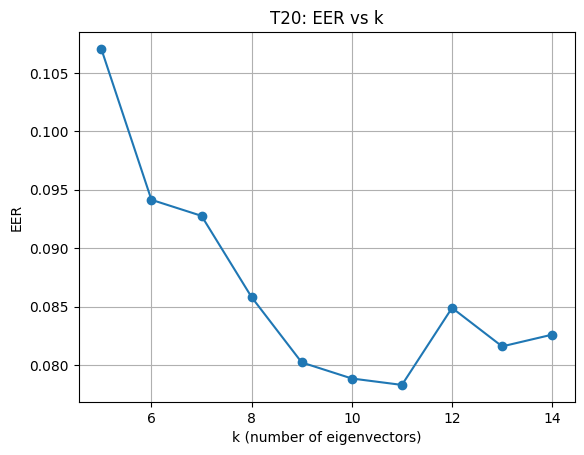

Best k (lowest EER) = 11


In [53]:
# INSERT CODE HERE
meanface_vec = meanface.reshape(-1)
ks = list(range(5, 15))

T_proj = calculate_projection_vectors(T, meanface_vec, v)
D_proj = calculate_projection_vectors(D, meanface_vec, v)

eer_list = []

for k in ks:
    sim_k = generate_similarity_matrix(T_proj[:, :k], D_proj[:, :k])

    tpr_list, fpr_list = calculate_roc(sim_k)
    tpr_list = np.array(tpr_list)
    fpr_list = np.array(fpr_list)
    fnr_list = 1 - tpr_list

    eer_idx = np.argmin(np.abs(fpr_list - fnr_list))
    eer = fpr_list[eer_idx]

    eer_list.append(eer)

    recall_001 = tpr_list[np.argmin(np.abs(fpr_list - 0.001))]

    print(f"k={k} | EER={eer:.4f} | Recall@0.1%FAR={recall_001:.4f}")

plt.plot(ks, eer_list, marker="o")
plt.xlabel("k (number of eigenvectors)")
plt.ylabel("EER")
plt.title("T20: EER vs k")
plt.grid(True)
plt.show()

best_k = ks[np.argmin(eer_list)]
print("Best k (lowest EER) =", best_k)

**ANS:** k=11 have the best EER

### T21. In order to assure that $S_W$ is invertible we need to make sure that $S_W$ is full rank. How many PCA dimensions do we need to keep in order for $S_W$ to be full rank? (Hint: How many dimensions does $S_W$ have? In order to be of full rank, you need to have the same number of linearly independent factors)

In [55]:
# TODO: Define dimension of PCA.
num_people = 40
train_per_person = 3
N = num_people * train_per_person
C = num_people

# TODO: Find PCA of T and D with n_dim dimension.
d_max_full_rank = N - C

print("N (training samples) =", N)
print("C (classes) =", C)
print("Max PCA dimension for Sw to be full rank =", d_max_full_rank)


N (training samples) = 120
C (classes) = 40
Max PCA dimension for Sw to be full rank = 80


    ANS:

### T22. Using the answer to the previous question, project the original in- put to the PCA subspace. Find the LDA projections. To find the inverse, use âˆ’1 numpy.linalg.inv. Is $S_W$ $S_B$ symmetric? Can we still use numpy.linalg.eigh? How many non-zero eigenvalues are there?


In [ ]:
# TODO: Find the LDA projection.

In [ ]:
# TODO: Find how many non-zero eigenvalues there are.

LDA is symmetric False


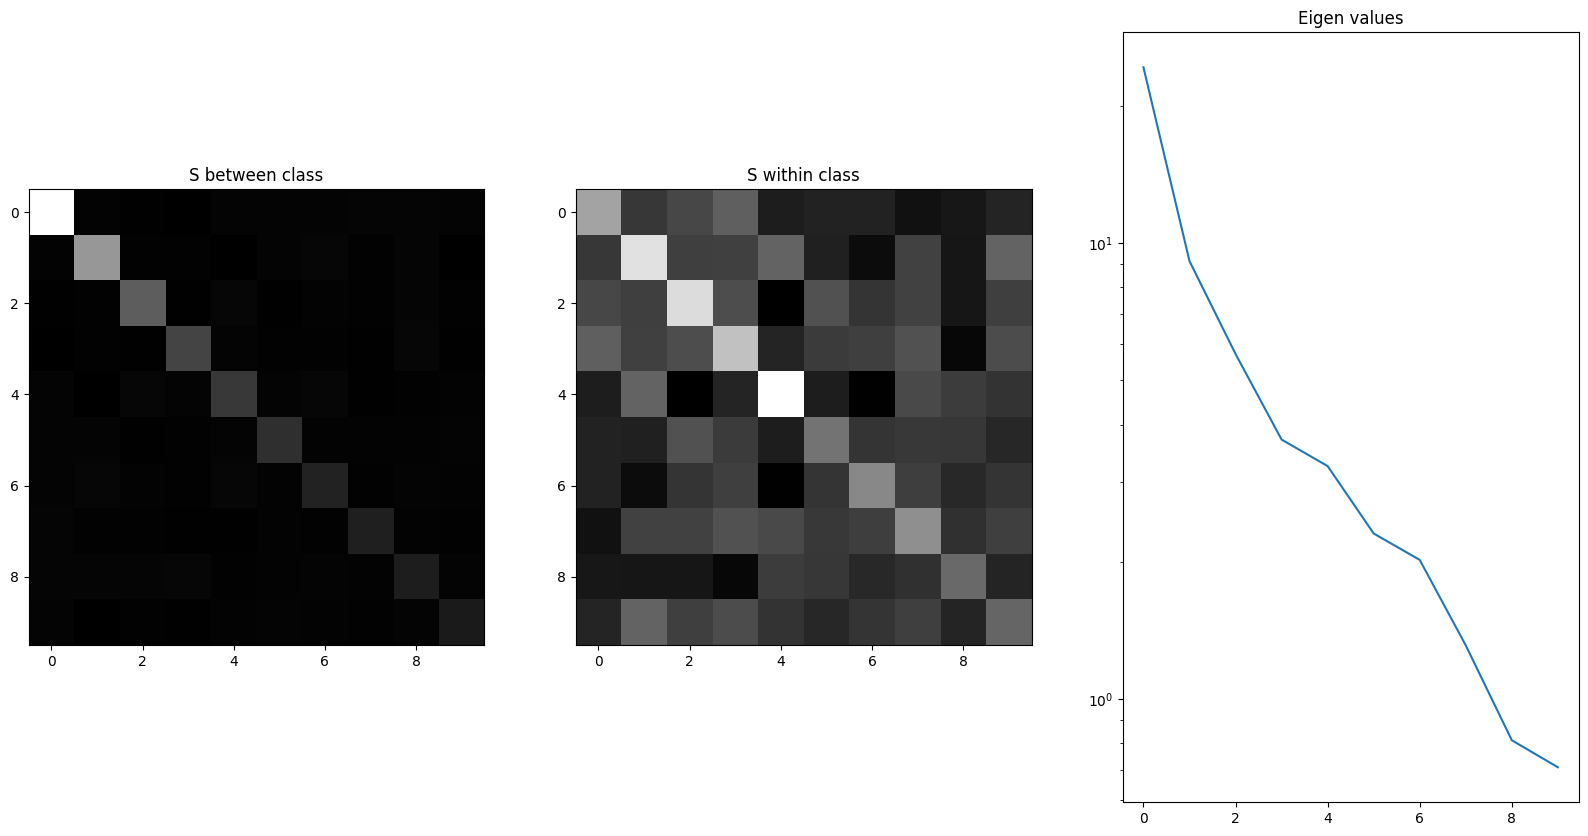

In [56]:
T_reduced_by_class = T_reduced.reshape((40, 3, -1))
class_mean = T_reduced_by_class.mean(axis=1)
all_mean = class_mean.mean(axis=0).reshape(1, -1)

s_b = np.array([(class_mean[i]-all_mean).T @(class_mean[i]-all_mean) for i in range(class_mean.shape[0])]).sum(axis=0)

s_wi = np.array([(T_reduced_by_class[i]-class_mean[i]).T @ (T_reduced_by_class[i]-class_mean[i]) for i in range(class_mean.shape[0])])
s_w = s_wi.sum(axis=0)

LDA = np.linalg.inv(s_w) @ s_b
print("LDA is symmetric", np.allclose(LDA, LDA.T))
LDA_eigenvalues, LDA_eigenvectors = np.linalg.eig(LDA)

LDA_eigenvectors = LDA_eigenvectors.real
LDA_eigenvalues = LDA_eigenvalues.real

plt.figure(figsize=(20, 10))
plt.subplot(1, 3, 1)
plt.imshow(s_b, cmap='gray')
plt.title("S between class")
plt.subplot(1, 3, 2)
plt.imshow(s_w, cmap='gray')
plt.title("S within class")
plt.subplot(1, 3, 3)
plt.title("Eigen values")
plt.plot(LDA_eigenvalues)
plt.yscale('log')

plt.show()

In [62]:
non_zero = np.count_nonzero(np.abs(LDA_eigenvalues) > 1e-10)
print("Number of non-zero eigenvalues:", non_zero)

Number of non-zero eigenvalues: 10


    ANS:

### T23. Plot the first 10 LDA eigenvectors as images (the 10 best projections). Note that in this setup, you need to convert back to the original image space by using the PCA projection. The LDA eigenvectors can be considered as a linear combination of eigenfaces. Compare the LDA projections with the PCA projections.

In [ ]:
# INSERT CODE HERE

### T24. The combined PCA+LDA projection procedure is called fisherface. Calculate the fisherfaces projection of all images. Do the simple face verification experiment using fisherfaces. What is the EER and recall rate at 0.1% FAR?

In [ ]:
# INSERT CODE HERE

    ANS:

### T25.Plot the RoC of all three experiments (No projection, PCA, andFisher) on the same axes. Compare and contrast the three results. Submit yourwriteup and code on MyCourseVille.

In [ ]:
# INSERT CODE HERE

    ANS: